# 01 — Data Exploration and Validation

## UCU Artificial Intelligence 2026 — Homework 4

### Objectives

- Inspect the dataset structure and verify data integrity.
- Analyze mathematical skill distribution.
- Examine target answer formats.
- Analyze the availability of steps, hints, and typical errors.
- Create a fixed stratified training and validation split.
- Establish a reproducible foundation for all experiments.

In [45]:
from pathlib import Path
import json
import hashlib
import random
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(
    style="whitegrid",
    palette="deep"
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Imports completed successfully.")

Imports completed successfully.


All required libraries were imported successfully. The random seed was fixed at 42 for reproducibility.

## 1. Project Configuration

In [46]:
PROJECT_ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "data" / "train.csv").exists()
)

DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
CONFIGS_DIR = PROJECT_ROOT / "configs"
IMAGES_DIR = PROJECT_ROOT / "images"

VALIDATION_SIZE = 0.20

print("Project root:", PROJECT_ROOT.name)
print("Data directory:", DATA_DIR.relative_to(PROJECT_ROOT))
print("Random seed:", SEED)
print("Validation size:", VALIDATION_SIZE)

Project root: ucu-ai-hw4
Data directory: data
Random seed: 42
Validation size: 0.2


The project root and data directory were identified successfully. A fixed random seed of 42 and a validation size of 20% were configured for subsequent experiments.

## 2. Data Loading

In [47]:
train = pd.read_csv(
    DATA_DIR / "train.csv",
    dtype=str,
    keep_default_na=False
)

test = pd.read_csv(
    DATA_DIR / "test.csv",
    dtype=str,
    keep_default_na=False
)

sample_submission = pd.read_csv(
    DATA_DIR / "sample_submission.csv",
    dtype=str,
    keep_default_na=False
)

dataset_summary = pd.DataFrame({
    "Dataset": [
        "Train",
        "Test",
        "Sample Submission"
    ],
    "Rows": [
        train.shape[0],
        test.shape[0],
        sample_submission.shape[0]
    ],
    "Columns": [
        train.shape[1],
        test.shape[1],
        sample_submission.shape[1]
    ]
})

display(dataset_summary)

,Dataset,Rows,Columns
0,Train,1526,8
1,Test,3561,4
2,Sample Submission,3561,2


All three datasets were loaded successfully. The training dataset contains 1,526 problems, while the test dataset contains 3,561 problems. The sample submission contains the expected number of rows.

## 3. Dataset Schema

In [48]:
schema_summary = pd.DataFrame({
    "Column": train.columns,
    "Train": [
        col in train.columns
        for col in train.columns
    ],
    "Test": [
        col in test.columns
        for col in train.columns
    ],
    "Sample Submission": [
        col in sample_submission.columns
        for col in train.columns
    ]
})

display(schema_summary)

,Column,Train,Test,Sample Submission
0,id,True,True,True
1,skill,True,True,False
2,skill_title,True,True,False
3,statement,True,True,False
4,answer,True,False,True
5,steps,True,False,False
6,hints,True,False,False
7,typical_errors,True,False,False


The training dataset contains eight columns, including ground-truth answers and supplementary information (steps, hints, and typical errors). The test dataset contains only four input columns, without ground-truth answers.

## 4. Data Integrity Checks

In [49]:
expected_train_columns = [
    "id",
    "skill",
    "skill_title",
    "statement",
    "answer",
    "steps",
    "hints",
    "typical_errors"
]

expected_test_columns = [
    "id",
    "skill",
    "skill_title",
    "statement"
]

integrity_checks = {
    "Correct train size": len(train) == 1526,

    "Correct test size": len(test) == 3561,

    "Correct submission size":
        len(sample_submission) == 3561,

    "Correct train schema":
        list(train.columns) == expected_train_columns,

    "Correct test schema":
        list(test.columns) == expected_test_columns,

    "Unique train IDs":
        train["id"].is_unique,

    "Unique test IDs":
        test["id"].is_unique,

    "Unique submission IDs":
        sample_submission["id"].is_unique,

    "No train-test ID overlap":
        set(train["id"]).isdisjoint(test["id"]),

    "Matching test and submission IDs":
        set(test["id"]) == set(sample_submission["id"]),

    "Correct submission schema":
        list(sample_submission.columns) == ["id", "answer"],

    "Correct number of skills":
        train["skill"].nunique() == 29,

    "Matching train and test skills":
        set(train["skill"]) == set(test["skill"]),

    "No duplicated train statements":
        not train["statement"].duplicated().any(),

    "No empty training statements":
        train["statement"].str.strip().ne("").all(),

    "No empty training answers":
        train["answer"].str.strip().ne("").all()
}

integrity_summary = pd.DataFrame({
    "Check": list(integrity_checks.keys()),
    "Status": [
        "PASS" if passed else "FAIL"
        for passed in integrity_checks.values()
    ]
})

display(integrity_summary)

assert all(integrity_checks.values()), (
    "Dataset integrity validation failed."
)

print(
    f"All {len(integrity_checks)} "
    "integrity checks passed."
)

,Check,Status
0,Correct train size,PASS
1,Correct test size,PASS
2,Correct submission size,PASS
3,Correct train schema,PASS
4,Correct test schema,PASS
5,Unique train IDs,PASS
6,Unique test IDs,PASS
7,Unique submission IDs,PASS
8,No train-test ID overlap,PASS
9,Matching test and submission IDs,PASS


All 16 integrity checks passed.


All 16 integrity checks passed. Dataset sizes, schemas, unique identifiers, and skill coverage are consistent with the assignment requirements. No overlapping train-test IDs or duplicated training statements were detected.

### 4.1. Missing and Empty Values

In [50]:
missing_summary = pd.DataFrame({
    "Column": train.columns,

    "Missing Values": train.isna().sum().values,

    "Empty Strings": [
        train[col].str.strip().eq("").sum()
        for col in train.columns
    ]
})

display(missing_summary)

,Column,Missing Values,Empty Strings
0,id,0,0
1,skill,0,0
2,skill_title,0,0
3,statement,0,0
4,answer,0,0
5,steps,0,0
6,hints,0,0
7,typical_errors,0,0


No missing values or empty strings were detected in the training dataset. However, supplementary fields may contain empty structured values, which require separate inspection.

### 4.2. Dataset Fingerprint

In [51]:
train_fingerprint = hashlib.sha256(
    (DATA_DIR / "train.csv").read_bytes()
).hexdigest()

print("Train dataset SHA-256:")
print(train_fingerprint)

Train dataset SHA-256:
25b1abba55d2fc3585e0910c12a600b8ef2871914c417a7d3ff16a66f7b9a961


A SHA-256 fingerprint was generated for the original training dataset. It will be used to verify data consistency across environments and experiments.

## 5. Skill Distribution Analysis

### 5.1. Training Skill Distribution

Analyze the number and proportion of training problems across mathematical skills to identify potential data imbalance.

In [52]:
skill_distribution = (
    train.groupby(["skill", "skill_title"])
    .size()
    .reset_index(name="count")
    .sort_values(["count", "skill"], ascending=[False, True])
    .reset_index(drop=True)
)

skill_distribution["percentage"] = (
    skill_distribution["count"] / len(train) * 100
).round(2)

display(skill_distribution)

,skill,skill_title,count,percentage
0,AVG,Середнє арифметичне,60,3.93
1,D-MUL10,"Множення й ділення десяткових на 10, 100, 1000",60,3.93
2,D-SUB,Віднімання десяткових дробів,60,3.93
3,EQ-ADD-SUB,Рівняння: додавання й віднімання,60,3.93
4,N-ADD-MULTI,Додавання багатоцифрових чисел стовпчиком,60,3.93
5,N-DIVTEST,Ознаки подільності,60,3.93
6,N-MUL-MULTI,Множення багатоцифрового числа на одноцифрове й двоцифрове,60,3.93
7,N-ORDER,Порядок дій у виразах з додаванням і множенням,60,3.93
8,N-ROUND,Округлення натуральних чисел,60,3.93
9,N-SUB-MULTI,Віднімання багатоцифрових чисел стовпчиком,60,3.93


The training dataset covers 29 mathematical skills. Most skills contain a similar number of problems, although several categories have noticeably fewer training examples.

### 5.2. Skill Distribution Statistics

In [53]:
skill_statistics = pd.DataFrame({
    "Metric": [
        "Number of skills",
        "Total problems",
        "Mean problems per skill",
        "Median problems per skill",
        "Minimum problems per skill",
        "Maximum problems per skill",
        "Standard deviation",
        "Max-to-min ratio"
    ],
    "Value": [
        len(skill_distribution),
        skill_distribution["count"].sum(),
        skill_distribution["count"].mean(),
        skill_distribution["count"].median(),
        skill_distribution["count"].min(),
        skill_distribution["count"].max(),
        skill_distribution["count"].std(),
        (
            skill_distribution["count"].max()
            / skill_distribution["count"].min()
        )
    ]
})

skill_statistics["Value"] = (
    skill_statistics["Value"].round(2)
)

display(skill_statistics)

,Metric,Value
0,Number of skills,29.00
1,Total problems,1526.00
2,Mean problems per skill,52.62
3,Median problems per skill,58.00
4,Minimum problems per skill,15.00
5,Maximum problems per skill,60.00
6,Standard deviation,12.29
7,Max-to-min ratio,4.00


The mean and median numbers of problems per skill are 52.62 and 58, respectively. Skill sizes range from 15 to 60 problems, resulting in a maximum-to-minimum ratio of 4.0.

### 5.3. Skill Distribution Visualization

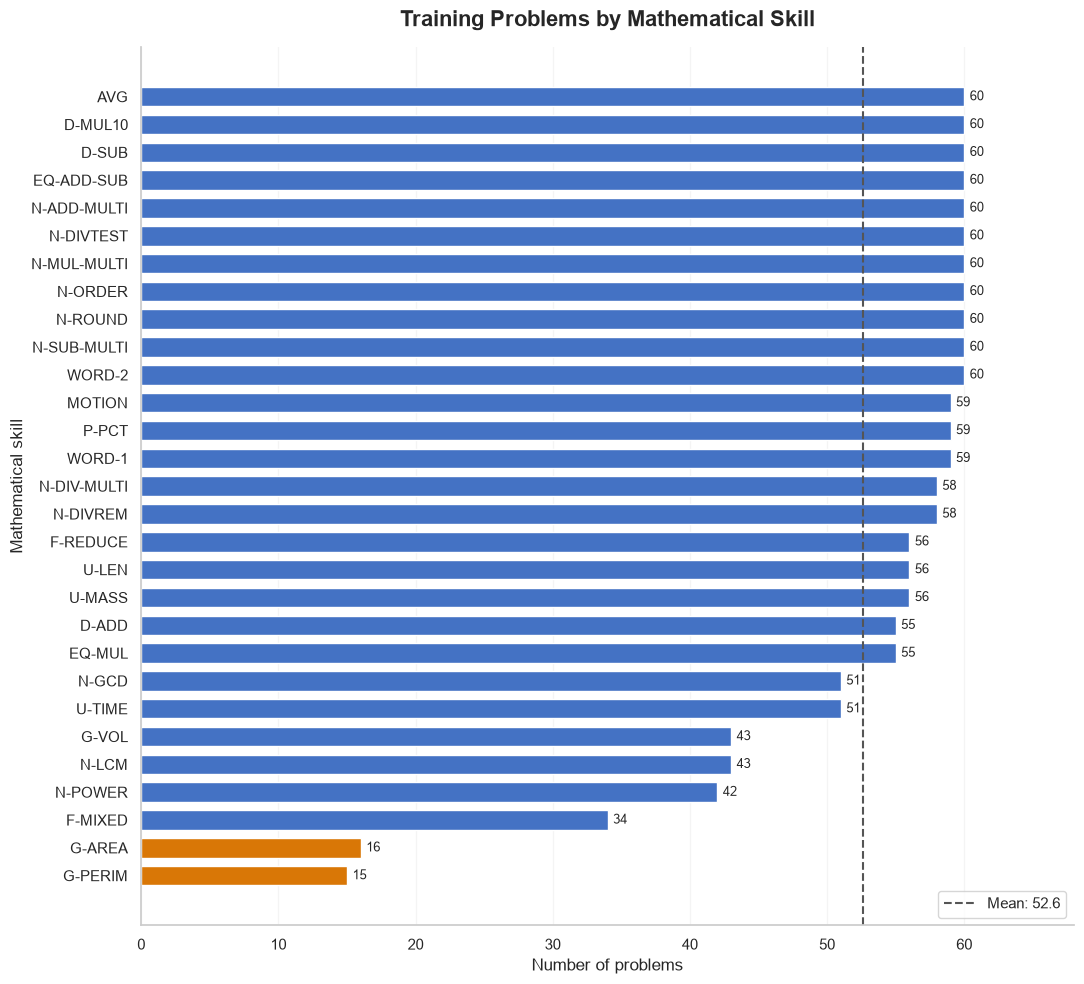

In [54]:
plot_data = skill_distribution.sort_values(
    ["count", "skill"],
    ascending=[True, False]
)

mean_count = skill_distribution["count"].mean()

colors = [
    "#D97706" if count < 20 else "#4472C4"
    for count in plot_data["count"]
]

fig, ax = plt.subplots(figsize=(11, 10))

bars = ax.barh(
    plot_data["skill"],
    plot_data["count"],
    color=colors,
    height=0.7
)

ax.bar_label(
    bars,
    padding=4,
    fontsize=9
)

ax.axvline(
    mean_count,
    color="#555555",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_count:.1f}"
)

ax.set_title(
    "Training Problems by Mathematical Skill",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of problems")
ax.set_ylabel("Mathematical skill")
ax.set_xlim(0, 68)

ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

ax.legend(loc="lower right")

sns.despine()
plt.tight_layout()

plt.show()

Most mathematical skills have between 50 and 60 training problems. However, geometry skills G-AREA and G-PERIM are substantially underrepresented.

### 5.4. Underrepresented Skills

Identify mathematical skills with limited training examples that may require additional attention during model evaluation and training.

In [55]:
LOW_SUPPORT_THRESHOLD = 20

underrepresented_skills = (
    skill_distribution[
        skill_distribution["count"] < LOW_SUPPORT_THRESHOLD
    ]
    .sort_values("count")
    .reset_index(drop=True)
)

display(underrepresented_skills)

print(
    "Number of underrepresented skills:",
    len(underrepresented_skills)
)

print(
    "Total problems in underrepresented skills:",
    underrepresented_skills["count"].sum()
)

print(
    "Share of training dataset:",
    f"{underrepresented_skills['count'].sum() / len(train):.2%}"
)

,skill,skill_title,count,percentage
0,G-PERIM,Периметр прямокутника й квадрата,15,0.98
1,G-AREA,Площа прямокутника й квадрата,16,1.05


Number of underrepresented skills: 2
Total problems in underrepresented skills: 31
Share of training dataset: 2.03%


G-PERIM and G-AREA are the only skills with fewer than 20 training examples. Together, they account for 31 problems (2.03% of the training dataset). Their performance should be monitored during validation.

### 5.5. Skill Metadata Consistency

In [56]:
skill_title_counts = (
    train.groupby("skill")["skill_title"]
    .nunique()
)

metadata_checks = {
    "Unique skill codes": train["skill"].nunique(),
    "Unique skill titles": train["skill_title"].nunique(),
    "Skills with inconsistent titles": (
        skill_title_counts > 1
    ).sum()
}

for name, value in metadata_checks.items():
    print(f"{name}: {value}")

assert skill_title_counts.eq(1).all()

print("\nSkill metadata validation passed.")

Unique skill codes: 29
Unique skill titles: 29
Skills with inconsistent titles: 0

Skill metadata validation passed.


All 29 mathematical skills have consistent and unique skill titles. The metadata can be used reliably for stratified sampling, skill-level evaluation, and skill-aware prompting.

### 5.6. Save Skill Analysis Results

In [57]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

skill_distribution.to_csv(
    RESULTS_DIR / "skill_distribution.csv",
    index=False
)

skill_statistics.to_csv(
    RESULTS_DIR / "skill_statistics.csv",
    index=False
)

print("Saved: results/skill_distribution.csv")
print("Saved: results/skill_statistics.csv")

Saved: results/skill_distribution.csv
Saved: results/skill_statistics.csv


Skill distribution and summary statistics were exported for future analysis and experiment comparison.

## 6. Answer Format Analysis

The competition uses exact-match accuracy, making answer formatting an important part of the inference pipeline. This section examines the representation of ground-truth answers in the training dataset.

### 6.1. Answer Format Classification

In [58]:
def classify_answer_format(answer):
    answer = str(answer).strip()

    if re.fullmatch(r"-?(0|[1-9][0-9]*)", answer):
        return "Integer"

    if re.fullmatch(r"-?[0-9]+\.[0-9]+", answer):
        return "Decimal"

    if re.fullmatch(r"-?[0-9]+/[0-9]+", answer):
        return "Fraction"

    return "Other"


answer_formats = train[["id", "skill", "answer"]].copy()

answer_formats["answer_format"] = (
    answer_formats["answer"].apply(classify_answer_format)
)

answer_format_distribution = (
    answer_formats["answer_format"]
    .value_counts()
    .rename_axis("answer_format")
    .reset_index(name="count")
)

answer_format_distribution["percentage"] = (
    answer_format_distribution["count"] / len(train) * 100
).round(2)

display(answer_format_distribution)

,answer_format,count,percentage
0,Integer,1366,89.52
1,Decimal,136,8.91
2,Fraction,24,1.57


Integer answers dominate the training dataset, accounting for approximately 89.5% of all problems. Decimal and fractional answers are less frequent but require careful handling to avoid exact-match evaluation errors.

### 6.2. Answer Format Distribution

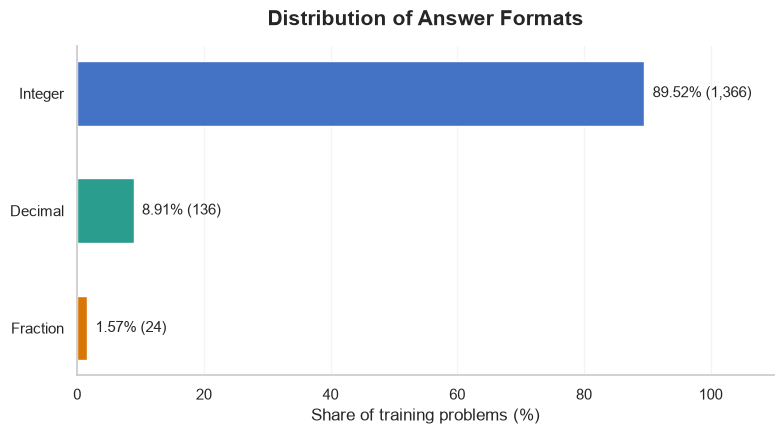

In [59]:
format_colors = {
    "Integer": "#4472C4",
    "Decimal": "#2A9D8F",
    "Fraction": "#D97706",
    "Other": "#9CA3AF"
}

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    answer_format_distribution["answer_format"],
    answer_format_distribution["percentage"],
    color=[
        format_colors[fmt]
        for fmt in answer_format_distribution["answer_format"]
    ],
    height=0.55
)

labels = [
    f"{pct:.2f}% ({count:,})"
    for pct, count in zip(
        answer_format_distribution["percentage"],
        answer_format_distribution["count"]
    )
]

ax.bar_label(
    bars,
    labels=labels,
    padding=6,
    fontsize=11
)

ax.invert_yaxis()

ax.set_title(
    "Distribution of Answer Formats",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Share of training problems (%)")
ax.set_xlim(0, 110)

ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

Although non-integer answers represent only a small proportion of the dataset, incorrect decimal separators, trailing zeros, or unreduced fractions can lead to otherwise correct predictions being marked as incorrect.

### 6.3. Canonical Answer Validation

Verify that the provided ground-truth answers comply with the competition's canonical answer format.

In [60]:
from decimal import Decimal
from fractions import Fraction


def is_canonical_answer(answer):
    answer = str(answer)
    answer_type = classify_answer_format(answer)

    try:
        if answer_type == "Integer":
            return str(int(answer)) == answer

        if answer_type == "Decimal":
            value = Decimal(answer)

            normalized = format(
                value.normalize(),
                "f"
            )

            return normalized == answer

        if answer_type == "Fraction":
            value = Fraction(answer)

            return str(value) == answer

        return False

    except (ValueError, ArithmeticError):
        return False


answer_formats["is_canonical"] = (
    answer_formats["answer"].apply(is_canonical_answer)
)

canonical_summary = (
    answer_formats.groupby("answer_format")
    .agg(
        total=("is_canonical", "size"),
        canonical=("is_canonical", "sum")
    )
    .reset_index()
)

canonical_summary["non_canonical"] = (
    canonical_summary["total"]
    - canonical_summary["canonical"]
)

display(canonical_summary)

print(
    "All answers are canonical:",
    answer_formats["is_canonical"].all()
)

assert answer_formats["is_canonical"].all()

,answer_format,total,canonical,non_canonical
0,Decimal,136,136,0
1,Fraction,24,24,0
2,Integer,1366,1366,0


All answers are canonical: True


All ground-truth answers comply with the required canonical format. No additional cleaning of the target column is necessary. Future model predictions will need to follow the same formatting conventions.

### 6.4. Answer Formats by Mathematical Skill

Examine whether answer representations vary across mathematical skills.

In [61]:
skill_answer_formats = pd.crosstab(
    answer_formats["skill"],
    answer_formats["answer_format"]
)

skill_answer_formats = skill_answer_formats.reindex(
    columns=["Integer", "Decimal", "Fraction", "Other"],
    fill_value=0
)

skill_answer_formats["Total"] = (
    skill_answer_formats.sum(axis=1)
)

skill_answer_formats = (
    skill_answer_formats
    .sort_index()
)

display(skill_answer_formats)

answer_format,Integer,Decimal,Fraction,Other,Total
skill,,,,,
AVG,60,0,0,0,60
D-ADD,11,44,0,0,55
D-MUL10,20,32,8,0,60
D-SUB,0,60,0,0,60
EQ-ADD-SUB,60,0,0,0,60
EQ-MUL,55,0,0,0,55
F-MIXED,18,0,16,0,34
F-REDUCE,56,0,0,0,56
G-AREA,16,0,0,0,16


Answer formats vary across mathematical skills, and some skills contain multiple representations. Therefore, the required answer format cannot be reliably determined from the skill code alone.

### 6.5. Answer Format Composition by Skill

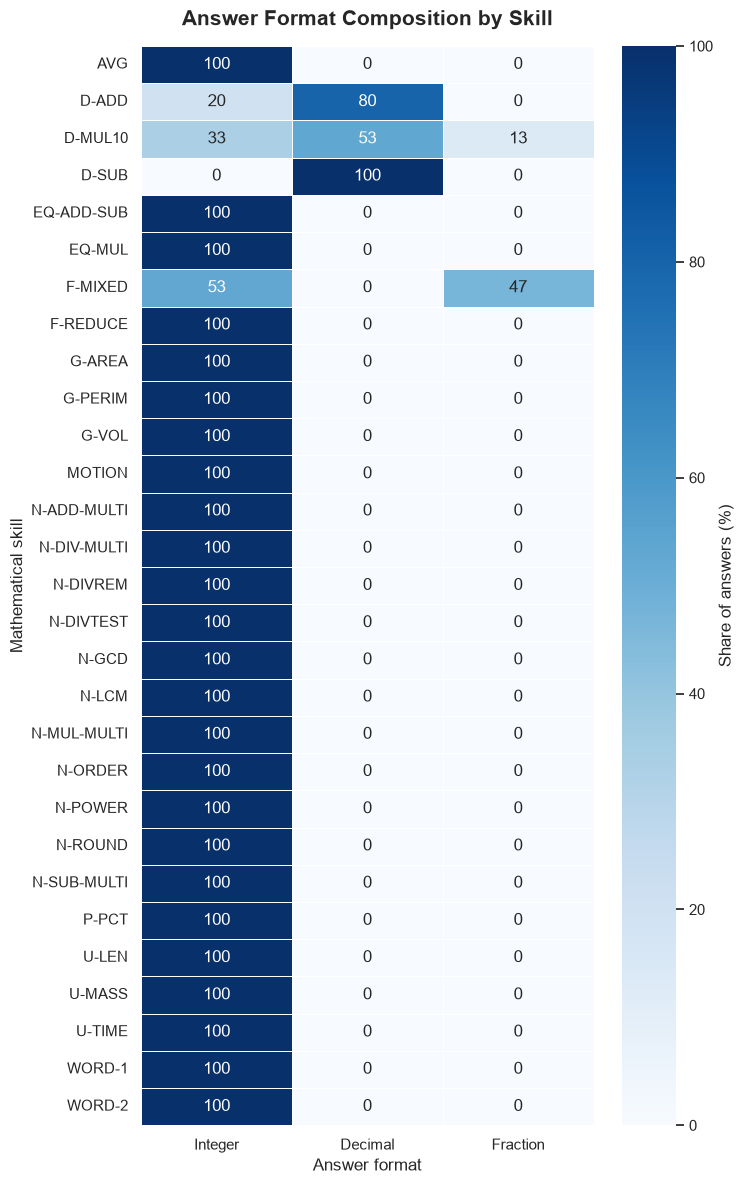

In [62]:
format_columns = [
    "Integer",
    "Decimal",
    "Fraction"
]

skill_format_percentages = (
    skill_answer_formats[format_columns]
    .div(skill_answer_formats["Total"], axis=0)
    .mul(100)
)

fig, ax = plt.subplots(figsize=(7.5, 12))

sns.heatmap(
    skill_format_percentages,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Share of answers (%)"},
    ax=ax
)

ax.set_title(
    "Answer Format Composition by Skill",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Answer format")
ax.set_ylabel("Mathematical skill")

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Most skills are associated with integer answers. Non-integer representations are concentrated in decimal arithmetic and mixed-number tasks. These categories will require particular attention when evaluating answer extraction and normalization.

### 6.6. Additional Answer Characteristics

In [63]:
decimal_answers = answer_formats.loc[
    answer_formats["answer_format"] == "Decimal",
    "answer"
]

decimal_precision = (
    decimal_answers
    .str.split(".")
    .str[1]
    .str.len()
)

answer_characteristics = pd.DataFrame({
    "Metric": [
        "Total answers",
        "Unique answers",
        "Negative answers",
        "Zero answers",
        "Minimum answer length",
        "Maximum answer length",
        "Minimum decimal places",
        "Maximum decimal places"
    ],
    "Value": [
        len(answer_formats),
        answer_formats["answer"].nunique(),
        answer_formats["answer"].str.startswith("-").sum(),
        answer_formats["answer"].eq("0").sum(),
        answer_formats["answer"].str.len().min(),
        answer_formats["answer"].str.len().max(),
        decimal_precision.min(),
        decimal_precision.max()
    ]
})

display(answer_characteristics)

,Metric,Value
0,Total answers,1526
1,Unique answers,769
2,Negative answers,0
3,Zero answers,0
4,Minimum answer length,1
5,Maximum answer length,8
6,Minimum decimal places,1
7,Maximum decimal places,6


The training dataset contains no zero or negative ground-truth answers. Decimal answers contain up to six decimal places, indicating that arbitrary rounding could introduce evaluation errors. These observations describe the training data rather than impose restrictions on future predictions.

### 6.7. Save Answer Format Analysis

In [64]:
answer_format_distribution.to_csv(
    RESULTS_DIR / "answer_format_distribution.csv",
    index=False
)

canonical_summary.to_csv(
    RESULTS_DIR / "canonical_answer_validation.csv",
    index=False
)

skill_answer_formats.to_csv(
    RESULTS_DIR / "skill_answer_formats.csv"
)

answer_characteristics.to_csv(
    RESULTS_DIR / "answer_characteristics.csv",
    index=False
)

print("Saved:")
print("  results/answer_format_distribution.csv")
print("  results/canonical_answer_validation.csv")
print("  results/skill_answer_formats.csv")
print("  results/answer_characteristics.csv")

Saved:
  results/answer_format_distribution.csv
  results/canonical_answer_validation.csv
  results/skill_answer_formats.csv
  results/answer_characteristics.csv


The aggregated answer format statistics have been saved for future reference. These findings will guide the development of the answer extraction and normalization components of the inference pipeline.

## 7. Steps, Hints and Typical Errors Analysis

The training dataset provides supplementary information that may support reasoning, supervised fine-tuning, knowledge distillation, and preference optimization.

### 7.1. Parsing Structured Fields

In [65]:
supplementary = train[
    ["id", "skill", "answer", "steps", "hints", "typical_errors"]
].copy()

structured_columns = [
    "steps",
    "hints",
    "typical_errors"
]

for column in structured_columns:
    supplementary[column] = (
        supplementary[column].apply(json.loads)
    )

    assert supplementary[column].apply(
        lambda value: isinstance(value, list)
    ).all()

supplementary["n_steps"] = supplementary["steps"].str.len()
supplementary["n_hints"] = supplementary["hints"].str.len()
supplementary["n_errors"] = supplementary["typical_errors"].str.len()

print("All supplementary fields parsed successfully.")

display(
    supplementary[
        ["n_steps", "n_hints", "n_errors"]
    ].describe().round(2)
)

All supplementary fields parsed successfully.


,n_steps,n_hints,n_errors
count,1526.00,1526.0,1526.00
mean,0.52,3.0,1.46
std,0.58,0.0,0.50
min,0.00,3.0,1.00
25%,0.00,3.0,1.00
50%,0.00,3.0,1.00
75%,1.00,3.0,2.00
max,2.00,3.0,2.00


All supplementary fields were successfully converted from JSON strings into Python lists. Their original representations remain unchanged in the training dataset.

### 7.2. Supplementary Information Coverage

In [66]:
coverage_rows = []

for field, count_column in [
    ("Steps", "n_steps"),
    ("Hints", "n_hints"),
    ("Typical errors", "n_errors")
]:
    counts = supplementary[count_column]

    coverage_rows.append({
        "field": field,
        "problems_with_data": counts.gt(0).sum(),
        "problems_without_data": counts.eq(0).sum(),
        "coverage_pct": counts.gt(0).mean() * 100,
        "total_entries": counts.sum(),
        "mean_entries": counts.mean(),
        "min_entries": counts.min(),
        "max_entries": counts.max()
    })

supplementary_coverage = pd.DataFrame(
    coverage_rows
).round(2)

display(supplementary_coverage)

,field,problems_with_data,problems_without_data,coverage_pct,total_entries,mean_entries,min_entries,max_entries
0,Steps,728,798,47.71,792,0.52,0,2
1,Hints,1526,0,100.00,4578,3.00,3,3
2,Typical errors,1526,0,100.00,2223,1.46,1,2


Intermediate values are available for 728 problems (47.71%), while hints and typical errors are provided for every training problem. The latter two fields offer consistent supplementary supervision across all mathematical skills.

### 7.3. Distribution of Supplementary Entries

In [67]:
entry_distribution = pd.concat(
    {
        "Steps": supplementary["n_steps"].value_counts(),
        "Hints": supplementary["n_hints"].value_counts(),
        "Typical errors": supplementary["n_errors"].value_counts()
    },
    axis=1
).fillna(0).astype(int).sort_index()

entry_distribution.index.name = "Number of entries"

display(entry_distribution)

,Steps,Hints,Typical errors
Number of entries,,,
0,798,0,0
1,664,0,829
2,64,0,697
3,0,1526,0


Every problem includes exactly three hints and either one or two typical errors. Intermediate values are less consistent, with most problems containing zero or one recorded step.

### 7.4. Supplementary Information by Mathematical Skill

Examine how the availability of supplementary supervision varies across mathematical skills.

In [68]:
skill_supplementary = (
    supplementary
    .assign(has_steps=supplementary["n_steps"].gt(0))
    .groupby("skill")
    .agg(
        problems=("id", "size"),
        problems_with_steps=("has_steps", "sum"),
        mean_steps=("n_steps", "mean"),
        mean_hints=("n_hints", "mean"),
        mean_errors=("n_errors", "mean")
    )
)

skill_supplementary["steps_coverage_pct"] = (
    skill_supplementary["problems_with_steps"]
    / skill_supplementary["problems"]
    * 100
)

skill_supplementary = (
    skill_supplementary
    .sort_values(
        "steps_coverage_pct",
        ascending=False
    )
    .round(2)
)

display(skill_supplementary)

,problems,problems_with_steps,mean_steps,mean_hints,mean_errors,steps_coverage_pct
skill,,,,,,
AVG,60,60,1.00,3.0,2.00,100.00
N-ADD-MULTI,60,60,1.00,3.0,1.00,100.00
P-PCT,59,59,1.00,3.0,2.00,100.00
N-SUB-MULTI,60,60,1.00,3.0,1.00,100.00
N-ORDER,60,60,1.00,3.0,1.00,100.00
N-MUL-MULTI,60,60,2.00,3.0,1.00,100.00
D-ADD,55,55,1.00,3.0,1.00,100.00
N-DIV-MULTI,58,58,1.00,3.0,1.00,100.00
N-DIVREM,58,58,1.00,3.0,2.00,100.00


The availability of intermediate values differs substantially across skills. This suggests that the steps field cannot serve as a uniform source of reasoning supervision and should be complemented with other training information.

### 7.5. Typical Error Structure and Validation

In [69]:
errors_df = (
    supplementary[
        ["id", "skill", "answer", "typical_errors"]
    ]
    .explode("typical_errors")
    .dropna(subset=["typical_errors"])
    .reset_index(drop=True)
)

error_details = pd.json_normalize(
    errors_df.pop("typical_errors")
).rename(columns={
    "id": "error_type",
    "value": "wrong_answer",
    "explanation": "error_explanation"
})

errors_df = pd.concat(
    [errors_df, error_details],
    axis=1
)

error_checks = {
    "Expected error fields": {
        "error_type",
        "wrong_answer",
        "error_explanation"
    }.issubset(errors_df.columns),

    "No missing error types":
        errors_df["error_type"].notna().all(),

    "No empty explanations":
        errors_df["error_explanation"].str.strip().ne("").all(),

    "Wrong answers differ from correct answers":
        errors_df["wrong_answer"].ne(errors_df["answer"]).all(),

    "No duplicate wrong answers per problem":
        not errors_df.duplicated(
            subset=["id", "wrong_answer"]
        ).any()
}

error_checks["No numerically equivalent wrong answers"] = all(
    Fraction(wrong) != Fraction(correct)
    for wrong, correct in zip(
        errors_df["wrong_answer"],
        errors_df["answer"]
    )
)

for check, passed in error_checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {check}")

assert all(error_checks.values())

print("\nTotal typical errors:", len(errors_df))
print("Unique error types:", errors_df["error_type"].nunique())

[PASS] Expected error fields
[PASS] No missing error types
[PASS] No empty explanations
[PASS] Wrong answers differ from correct answers
[PASS] No duplicate wrong answers per problem
[PASS] No numerically equivalent wrong answers

Total typical errors: 2223
Unique error types: 57


The dataset contains 2,223 typical wrong answers across 57 error types. All error records passed the structural and numerical consistency checks, making them potential candidates for preference-based training.

### 7.6. Typical Error Frequency

In [70]:
error_frequency = (
    errors_df["error_type"]
    .value_counts()
    .rename_axis("error_type")
    .reset_index(name="count")
)

error_frequency["percentage"] = (
    error_frequency["count"]
    / len(errors_df)
    * 100
).round(2)

display(error_frequency.head(10))

,error_type,count,percentage
0,wrong_direction,169,7.60
1,multiply_instead,110,4.95
2,add_instead,92,4.14
3,wrong_zeros,71,3.19
4,subtract_instead,61,2.74
5,forget_carry,60,2.70
6,divide_by_count_minus_one,60,2.70
7,smaller_from_larger,60,2.70
8,first_step_only,60,2.70
9,forgot_divide,60,2.70


The annotated errors cover incorrect operation selection, arithmetic mistakes, unit conversion issues, and incomplete reasoning. These annotations describe predefined misconceptions rather than observed model failures and can later be compared with actual inference errors.

### 7.7. Most Frequent Typical Errors

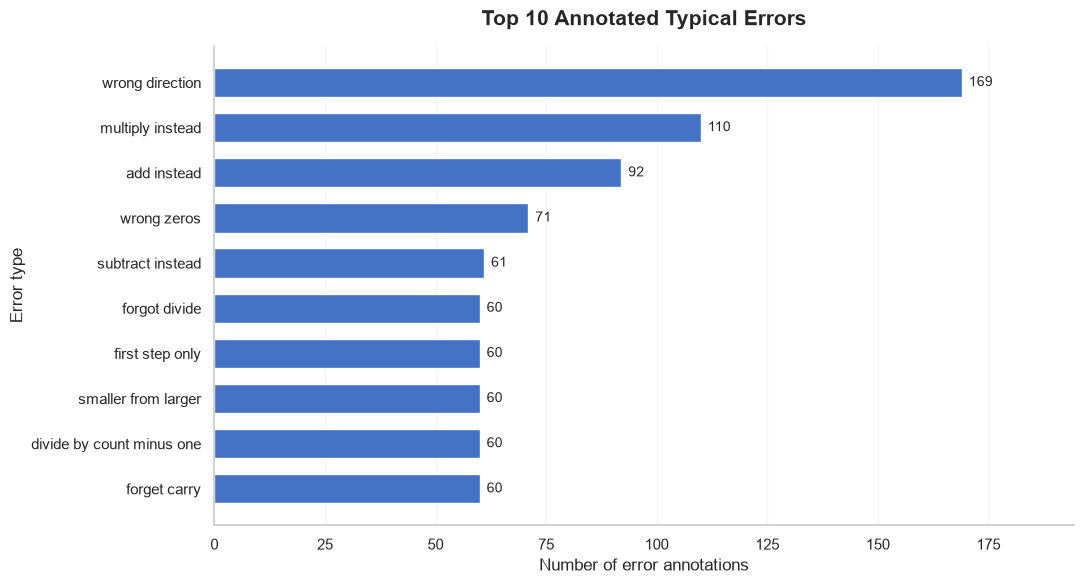

In [71]:
top_errors = (
    error_frequency
    .head(10)
    .sort_values("count")
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    top_errors["error_type"].str.replace("_", " "),
    top_errors["count"],
    color="#4472C4",
    height=0.65
)

ax.bar_label(
    bars,
    padding=5,
    fontsize=10
)

ax.set_title(
    "Top 10 Annotated Typical Errors",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of error annotations")
ax.set_ylabel("Error type")

ax.set_xlim(0, top_errors["count"].max() * 1.15)

ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

Incorrect conversion direction and incorrect operation selection are among the most frequently annotated misconceptions. Their relevance to the models will be assessed during subsequent error analysis.

### 7.8. Save Supplementary Analysis

In [72]:
supplementary_coverage.to_csv(
    RESULTS_DIR / "supplementary_coverage.csv",
    index=False
)

entry_distribution.to_csv(
    RESULTS_DIR / "supplementary_entry_distribution.csv"
)

skill_supplementary.to_csv(
    RESULTS_DIR / "skill_supplementary_statistics.csv"
)

error_frequency.to_csv(
    RESULTS_DIR / "typical_error_frequency.csv",
    index=False
)

print("Saved:")
print("  results/supplementary_coverage.csv")
print("  results/supplementary_entry_distribution.csv")
print("  results/skill_supplementary_statistics.csv")
print("  results/typical_error_frequency.csv")

Saved:
  results/supplementary_coverage.csv
  results/supplementary_entry_distribution.csv
  results/skill_supplementary_statistics.csv
  results/typical_error_frequency.csv


Aggregated supplementary information statistics have been saved. Individual problem statements, answers, and error explanations remain in the original dataset and are not included in the exported analysis files.

## 8. Fixed Stratified Validation Split

A fixed training and validation split is used to ensure consistent and fair comparison across all prompting, fine-tuning, and inference experiments.

The dataset is split into 80% training and 20% validation data, stratified by mathematical skill.

### 8.1. Create Training and Validation Sets

In [73]:
train_split, val_split = train_test_split(
    train,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=train["skill"],
    shuffle=True
)

train_split = (
    train_split
    .sort_index()
    .reset_index(drop=True)
)

val_split = (
    val_split
    .sort_index()
    .reset_index(drop=True)
)

split_summary = pd.DataFrame({
    "Dataset": [
        "Original training set",
        "Training split",
        "Validation split"
    ],
    "Problems": [
        len(train),
        len(train_split),
        len(val_split)
    ],
    "Percentage": [
        100.0,
        len(train_split) / len(train) * 100,
        len(val_split) / len(train) * 100
    ],
    "Unique skills": [
        train["skill"].nunique(),
        train_split["skill"].nunique(),
        val_split["skill"].nunique()
    ]
})

split_summary["Percentage"] = (
    split_summary["Percentage"].round(2)
)

display(split_summary)

,Dataset,Problems,Percentage,Unique skills
0,Original training set,1526,100.00,29
1,Training split,1220,79.95,29
2,Validation split,306,20.05,29


The original dataset was divided into 1,220 training and 306 validation problems. Both subsets retain all 29 mathematical skills. The same split will be used throughout the project.

### 8.2. Split Integrity Checks

Verify that the training and validation subsets are mutually exclusive, complete, and consistent with the original dataset.

In [74]:
original_ids = set(train["id"])
training_ids = set(train_split["id"])
validation_ids = set(val_split["id"])
test_ids = set(test["id"])

split_checks = {
    "Correct training size":
        len(train_split) == 1220,

    "Correct validation size":
        len(val_split) == 306,

    "No train-validation ID overlap":
        training_ids.isdisjoint(validation_ids),

    "All original IDs preserved":
        training_ids | validation_ids == original_ids,

    "Unique training IDs":
        train_split["id"].is_unique,

    "Unique validation IDs":
        val_split["id"].is_unique,

    "All skills present in training":
        set(train_split["skill"]) == set(train["skill"]),

    "All skills present in validation":
        set(val_split["skill"]) == set(train["skill"]),

    "No duplicated statements across splits":
        set(train_split["statement"]).isdisjoint(
            val_split["statement"]
        ),

    "No training-test ID overlap":
        training_ids.isdisjoint(test_ids),

    "No validation-test ID overlap":
        validation_ids.isdisjoint(test_ids)
}

split_integrity_summary = pd.DataFrame({
    "Check": list(split_checks.keys()),
    "Status": [
        "PASS" if passed else "FAIL"
        for passed in split_checks.values()
    ]
})

display(split_integrity_summary)

assert all(split_checks.values()), (
    "Data split validation failed."
)

print(f"All {len(split_checks)} split checks passed.")

,Check,Status
0,Correct training size,PASS
1,Correct validation size,PASS
2,No train-validation ID overlap,PASS
3,All original IDs preserved,PASS
4,Unique training IDs,PASS
5,Unique validation IDs,PASS
6,All skills present in training,PASS
7,All skills present in validation,PASS
8,No duplicated statements across splits,PASS
9,No training-test ID overlap,PASS


All 11 split checks passed.


The integrity checks confirm that the training and validation subsets contain no overlapping IDs or identical problem statements. All original training records are preserved, and neither subset overlaps with the competition test set by ID.

### 8.3. Skill Distribution Across Splits

Compare mathematical skill representation in the original dataset, training subset, and validation subset.

In [75]:
split_skill_distribution = pd.DataFrame({
    "original_count": train["skill"].value_counts(),
    "train_count": train_split["skill"].value_counts(),
    "validation_count": val_split["skill"].value_counts()
}).sort_index()

split_skill_distribution["original_pct"] = (
    split_skill_distribution["original_count"]
    / len(train) * 100
)

split_skill_distribution["train_pct"] = (
    split_skill_distribution["train_count"]
    / len(train_split) * 100
)

split_skill_distribution["validation_pct"] = (
    split_skill_distribution["validation_count"]
    / len(val_split) * 100
)

split_skill_distribution["validation_share_pct"] = (
    split_skill_distribution["validation_count"]
    / split_skill_distribution["original_count"]
    * 100
)

split_skill_distribution["distribution_difference_pp"] = (
    split_skill_distribution["validation_pct"]
    - split_skill_distribution["original_pct"]
)

display(split_skill_distribution.round(2))

,original_count,train_count,validation_count,original_pct,train_pct,validation_pct,validation_share_pct,distribution_difference_pp
skill,,,,,,,,
AVG,60,48,12,3.93,3.93,3.92,20.00,-0.01
D-ADD,55,44,11,3.60,3.61,3.59,20.00,-0.01
D-MUL10,60,48,12,3.93,3.93,3.92,20.00,-0.01
D-SUB,60,48,12,3.93,3.93,3.92,20.00,-0.01
EQ-ADD-SUB,60,48,12,3.93,3.93,3.92,20.00,-0.01
EQ-MUL,55,44,11,3.60,3.61,3.59,20.00,-0.01
F-MIXED,34,27,7,2.23,2.21,2.29,20.59,0.06
F-REDUCE,56,45,11,3.67,3.69,3.59,19.64,-0.07
G-AREA,16,13,3,1.05,1.07,0.98,18.75,-0.07


Stratification preserves the representation of mathematical skills across both subsets. Minor differences in proportions are expected because individual problems cannot be divided into fractional observations.

### 8.4. Skill Distribution Comparison

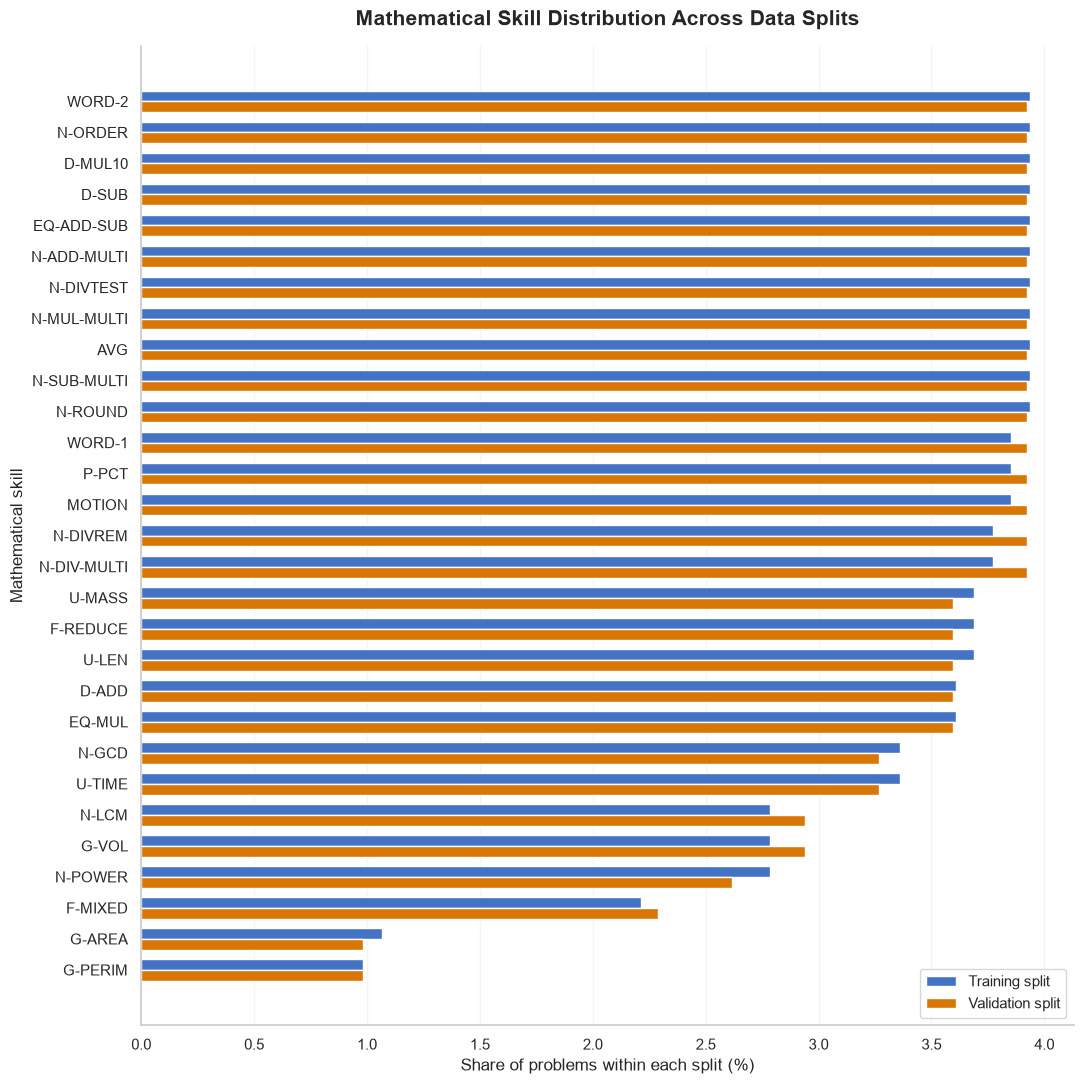

In [76]:
comparison_data = (
    split_skill_distribution
    .sort_values(
        "original_count",
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(11, 11))

positions = np.arange(len(comparison_data))
bar_height = 0.35

ax.barh(
    positions + bar_height / 2,
    comparison_data["train_pct"],
    height=bar_height,
    color="#4472C4",
    label="Training split"
)

ax.barh(
    positions - bar_height / 2,
    comparison_data["validation_pct"],
    height=bar_height,
    color="#D97706",
    label="Validation split"
)

ax.set_yticks(positions)
ax.set_yticklabels(comparison_data.index)

ax.set_title(
    "Mathematical Skill Distribution Across Data Splits",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Share of problems within each split (%)")
ax.set_ylabel("Mathematical skill")

ax.legend(loc="lower right")

ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

The relative skill distributions are closely aligned between the training and validation subsets, indicating that the stratified sampling procedure successfully maintains the original dataset composition.

### 8.5. Validation Set Representation

In [77]:
validation_support = (
    val_split["skill"]
    .value_counts()
    .sort_values()
)

validation_statistics = pd.DataFrame({
    "Metric": [
        "Validation problems",
        "Represented skills",
        "Minimum problems per skill",
        "Maximum problems per skill",
        "Mean problems per skill",
        "Skills with fewer than 5 problems",
        "Maximum distribution difference (pp)"
    ],
    "Value": [
        len(val_split),
        validation_support.size,
        validation_support.min(),
        validation_support.max(),
        validation_support.mean(),
        validation_support.lt(5).sum(),
        split_skill_distribution[
            "distribution_difference_pp"
        ].abs().max()
    ]
})

validation_statistics["Value"] = (
    validation_statistics["Value"].round(3)
)

display(validation_statistics)

print("\nSkills with fewer than 5 validation problems:")

display(
    validation_support[
        validation_support < 5
    ].to_frame("validation_count")
)

,Metric,Value
0,Validation problems,306.000
1,Represented skills,29.000
2,Minimum problems per skill,3.000
3,Maximum problems per skill,12.000
4,Mean problems per skill,10.552
5,Skills with fewer than 5 problems,2.000
6,Maximum distribution difference (pp),0.138



Skills with fewer than 5 validation problems:


,validation_count
skill,
G-PERIM,3
G-AREA,3


All mathematical skills are represented in the validation subset. However, some geometry skills have very limited validation support, which may lead to unstable skill-level accuracy estimates. Support counts should therefore accompany per-skill evaluation metrics.

### 8.6. Answer Format Representation Across Splits

Inspect the distribution of integer, decimal, and fractional answers in both subsets.

In [78]:
format_split_distribution = pd.DataFrame({
    "original_count": (
        train["answer"]
        .apply(classify_answer_format)
        .value_counts()
    ),
    "train_count": (
        train_split["answer"]
        .apply(classify_answer_format)
        .value_counts()
    ),
    "validation_count": (
        val_split["answer"]
        .apply(classify_answer_format)
        .value_counts()
    )
}).fillna(0).astype(int)

format_split_distribution["original_pct"] = (
    format_split_distribution["original_count"]
    / len(train) * 100
)

format_split_distribution["train_pct"] = (
    format_split_distribution["train_count"]
    / len(train_split) * 100
)

format_split_distribution["validation_pct"] = (
    format_split_distribution["validation_count"]
    / len(val_split) * 100
)

display(format_split_distribution.round(2))

print(
    "All answer formats present in training:",
    format_split_distribution["train_count"].gt(0).all()
)

print(
    "All answer formats present in validation:",
    format_split_distribution["validation_count"].gt(0).all()
)

,original_count,train_count,validation_count,original_pct,train_pct,validation_pct
answer,,,,,,
Integer,1366,1094,272,89.52,89.67,88.89
Decimal,136,109,27,8.91,8.93,8.82
Fraction,24,17,7,1.57,1.39,2.29


All answer formats present in training: True
All answer formats present in validation: True


Integer, decimal, and fractional answers are represented in both subsets. Although stratification was performed by mathematical skill rather than answer format, the resulting validation set allows evaluation across all three answer representations.

### 8.7. Separate Model Inputs from Supervision

Validation inference must use only information that is also available in the competition test dataset.

In [79]:
INPUT_COLUMNS = [
    "id",
    "skill",
    "skill_title",
    "statement"
]

SUPERVISION_COLUMNS = [
    "answer",
    "steps",
    "hints",
    "typical_errors"
]

val_inputs = val_split[INPUT_COLUMNS].copy()

val_targets = val_split[
    ["id", "answer"]
].copy()

assert list(val_inputs.columns) == list(test.columns)

assert set(val_inputs.columns).isdisjoint(
    SUPERVISION_COLUMNS
)

assert val_inputs["id"].equals(
    val_targets["id"]
)

print("Validation input shape:", val_inputs.shape)
print("Validation target shape:", val_targets.shape)

print("\nModel input columns:")
print(val_inputs.columns.tolist())

print("\nValidation inputs and targets successfully separated.")

Validation input shape: (306, 4)
Validation target shape: (306, 2)

Model input columns:
['id', 'skill', 'skill_title', 'statement']

Validation inputs and targets successfully separated.


Validation inputs contain only the fields available in the competition test dataset. Ground-truth answers are stored separately for evaluation, while supplementary annotations are excluded from validation prompts to prevent information leakage.

## 9. Save Data Splits and Metadata

The fixed data split is exported to ensure reproducibility across local and Kaggle environments. Validation inputs and ground-truth targets are stored separately to prevent accidental information leakage.

### 9.1. Export Training and Validation Data

In [80]:
split_files = {
    "train_split.csv": train_split,
    "validation_inputs.csv": val_inputs,
    "validation_targets.csv": val_targets
}

for filename, dataframe in split_files.items():
    output_path = DATA_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8"
    )

    print(
        f"Saved: {output_path.relative_to(PROJECT_ROOT)} "
        f"| Shape: {dataframe.shape}"
    )

Saved: data/train_split.csv | Shape: (1220, 8)
Saved: data/validation_inputs.csv | Shape: (306, 4)
Saved: data/validation_targets.csv | Shape: (306, 2)


The training subset retains all eight original columns, including supplementary supervision. Validation data is stored as separate input and target files, ensuring that inference uses only information available in the competition test dataset.

### 9.2. Save Split Configuration

Store the exact training and validation identifiers together with the split parameters and original dataset fingerprint.

In [81]:
import sklearn

CONFIGS_DIR.mkdir(parents=True, exist_ok=True)

split_config = {
    "split_name": "stratified_80_20_seed42",
    "source_dataset": "train.csv",
    "source_sha256": train_fingerprint,

    "random_state": SEED,
    "validation_size": VALIDATION_SIZE,
    "stratify_column": "skill",
    "shuffle": True,

    "total_samples": len(train),
    "train_samples": len(train_split),
    "validation_samples": len(val_split),
    "number_of_skills": train["skill"].nunique(),

    "sklearn_version": sklearn.__version__,

    "input_columns": INPUT_COLUMNS,
    "supervision_columns": SUPERVISION_COLUMNS,

    "train_ids": train_split["id"].tolist(),
    "validation_ids": val_split["id"].tolist()
}

SPLIT_CONFIG_PATH = CONFIGS_DIR / "validation_split.json"

with open(SPLIT_CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(
        split_config,
        file,
        indent=2,
        ensure_ascii=False
    )

print(
    "Saved:",
    SPLIT_CONFIG_PATH.relative_to(PROJECT_ROOT)
)

print("Training IDs:", len(split_config["train_ids"]))
print("Validation IDs:", len(split_config["validation_ids"]))
print("Random state:", split_config["random_state"])
print("Stratification:", split_config["stratify_column"])
print("Dataset SHA-256:", split_config["source_sha256"])

Saved: configs/validation_split.json
Training IDs: 1220
Validation IDs: 306
Random state: 42
Stratification: skill
Dataset SHA-256: 25b1abba55d2fc3585e0910c12a600b8ef2871914c417a7d3ff16a66f7b9a961


The split configuration records the random seed, stratification settings, dataset fingerprint, and exact sample identifiers. Saving identifiers rather than relying solely on the random seed allows the same subsets to be reconstructed across different computing environments.

### 9.3. Export Split Statistics

In [82]:
split_statistics_files = {
    "split_summary.csv": (
        split_summary,
        False
    ),
    "split_skill_distribution.csv": (
        split_skill_distribution.round(4),
        True
    ),
    "split_validation_statistics.csv": (
        validation_statistics,
        False
    ),
    "split_answer_format_distribution.csv": (
        format_split_distribution.round(4),
        True
    ),
    "split_integrity_checks.csv": (
        split_integrity_summary,
        False
    )
}

for filename, (dataframe, save_index) in (
    split_statistics_files.items()
):
    output_path = RESULTS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=save_index
    )

    print(
        f"Saved: {output_path.relative_to(PROJECT_ROOT)}"
    )

Saved: results/split_summary.csv
Saved: results/split_skill_distribution.csv
Saved: results/split_validation_statistics.csv
Saved: results/split_answer_format_distribution.csv
Saved: results/split_integrity_checks.csv


The exported statistics document the composition, integrity, and representativeness of the fixed data split. They provide a reference for interpreting future overall and skill-level evaluation metrics.

### 9.4. Verify Exported Data

Reload the exported datasets and compare them with their original in-memory representations.

In [83]:
for filename, original_dataframe in split_files.items():

    reloaded_dataframe = pd.read_csv(
        DATA_DIR / filename,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8"
    )

    pd.testing.assert_frame_equal(
        original_dataframe,
        reloaded_dataframe,
        check_dtype=True
    )

    print(
        f"[PASS] {filename}: "
        "content, columns and row order preserved."
    )

print("\nAll exported datasets verified successfully.")

[PASS] train_split.csv: content, columns and row order preserved.
[PASS] validation_inputs.csv: content, columns and row order preserved.
[PASS] validation_targets.csv: content, columns and row order preserved.

All exported datasets verified successfully.


All exported datasets were reloaded and compared with their original DataFrames. The verification confirms that values, column names, data types, and row ordering were preserved during serialization.

### 9.5. Verify Split Reproducibility

Reconstruct the fixed subsets from the original dataset and saved sample identifiers without performing random sampling again.

In [84]:
with open(
    SPLIT_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:
    loaded_config = json.load(file)


current_fingerprint = hashlib.sha256(
    (DATA_DIR / loaded_config["source_dataset"]).read_bytes()
).hexdigest()

assert current_fingerprint == loaded_config["source_sha256"]

original_data = pd.read_csv(
    DATA_DIR / loaded_config["source_dataset"],
    dtype=str,
    keep_default_na=False
)

indexed_train = original_data.set_index(
    "id",
    verify_integrity=True
)

reconstructed_train = (
    indexed_train
    .loc[loaded_config["train_ids"]]
    .reset_index()
)

reconstructed_validation = (
    indexed_train
    .loc[loaded_config["validation_ids"]]
    .reset_index()
)

pd.testing.assert_frame_equal(
    reconstructed_train,
    train_split
)

pd.testing.assert_frame_equal(
    reconstructed_validation,
    val_split
)

assert set(
    reconstructed_train["id"]
).isdisjoint(
    reconstructed_validation["id"]
)

print("[PASS] Original dataset fingerprint matches.")
print("[PASS] Training subset reconstructed exactly.")
print("[PASS] Validation subset reconstructed exactly.")
print("[PASS] No train-validation overlap.")

print("\nSplit reproducibility verified successfully.")

[PASS] Original dataset fingerprint matches.
[PASS] Training subset reconstructed exactly.
[PASS] Validation subset reconstructed exactly.
[PASS] No train-validation overlap.

Split reproducibility verified successfully.


Both subsets were reconstructed exactly using the saved identifiers and original training dataset. The matching dataset fingerprint and successful equality checks confirm that the fixed split can be reproduced without repeating the random sampling procedure.

## 10. Final Validation

Verify that all required data files, configuration files, and aggregated analysis results have been generated successfully.

### 10.1. Output Files Validation

In [85]:
expected_files = {
    "Data splits": [
        DATA_DIR / "train_split.csv",
        DATA_DIR / "validation_inputs.csv",
        DATA_DIR / "validation_targets.csv"
    ],

    "Configuration": [
        CONFIGS_DIR / "validation_split.json"
    ],

    "Skill analysis": [
        RESULTS_DIR / "skill_distribution.csv",
        RESULTS_DIR / "skill_statistics.csv"
    ],

    "Answer format analysis": [
        RESULTS_DIR / "answer_format_distribution.csv",
        RESULTS_DIR / "canonical_answer_validation.csv",
        RESULTS_DIR / "skill_answer_formats.csv",
        RESULTS_DIR / "answer_characteristics.csv"
    ],

    "Supplementary analysis": [
        RESULTS_DIR / "supplementary_coverage.csv",
        RESULTS_DIR / "supplementary_entry_distribution.csv",
        RESULTS_DIR / "skill_supplementary_statistics.csv",
        RESULTS_DIR / "typical_error_frequency.csv"
    ],

    "Split analysis": [
        RESULTS_DIR / "split_summary.csv",
        RESULTS_DIR / "split_skill_distribution.csv",
        RESULTS_DIR / "split_validation_statistics.csv",
        RESULTS_DIR / "split_answer_format_distribution.csv",
        RESULTS_DIR / "split_integrity_checks.csv"
    ]
}

file_validation = []

for category, paths in expected_files.items():
    for path in paths:
        exists = path.is_file()
        size = path.stat().st_size if exists else 0

        file_validation.append({
            "category": category,
            "file": str(path.relative_to(PROJECT_ROOT)),
            "size_kb": round(size / 1024, 2),
            "status": "PASS" if exists and size > 0 else "FAIL"
        })

file_validation_df = pd.DataFrame(file_validation)

display(file_validation_df)

assert file_validation_df["status"].eq("PASS").all()

print(
    f"All {len(file_validation_df)} "
    "required output files verified successfully."
)

,category,file,size_kb,status
0,Data splits,data/train_split.csv,1408.98,PASS
1,Data splits,data/validation_inputs.csv,45.08,PASS
2,Data splits,data/validation_targets.csv,3.24,PASS
3,Configuration,configs/validation_split.json,21.47,PASS
4,Skill analysis,results/skill_distribution.csv,2.12,PASS
5,Skill analysis,results/skill_statistics.csv,0.22,PASS
6,Answer format analysis,results/answer_format_distribution.csv,0.08,PASS
7,Answer format analysis,results/canonical_answer_validation.csv,0.10,PASS
8,Answer format analysis,results/skill_answer_formats.csv,0.61,PASS
9,Answer format analysis,results/answer_characteristics.csv,0.18,PASS


All 19 required output files verified successfully.


All 19 expected output files are present and non-empty, including the exported data subsets, split configuration, and aggregated exploratory statistics.

### 10.2. Final Dataset Summary

In [86]:
final_dataset_summary = pd.DataFrame({
    "Metric": [
        "Original training problems",
        "Training split problems",
        "Validation split problems",
        "Competition test problems",
        "Mathematical skills",
        "Integer answers",
        "Decimal answers",
        "Fractional answers",
        "Canonical answers",
        "Problems with intermediate steps",
        "Total intermediate values",
        "Total hints",
        "Total annotated typical errors",
        "Unique error types",
        "Random seed",
        "Validation proportion"
    ],

    "Value": [
        len(train),
        len(train_split),
        len(val_split),
        len(test),
        train["skill"].nunique(),

        answer_formats["answer_format"].eq("Integer").sum(),
        answer_formats["answer_format"].eq("Decimal").sum(),
        answer_formats["answer_format"].eq("Fraction").sum(),

        answer_formats["is_canonical"].sum(),

        supplementary["n_steps"].gt(0).sum(),
        supplementary["n_steps"].sum(),
        supplementary["n_hints"].sum(),

        len(errors_df),
        errors_df["error_type"].nunique(),

        SEED,
        f"{len(val_split) / len(train):.2%}"
    ]
})

display(final_dataset_summary)

,Metric,Value
0,Original training problems,1526
1,Training split problems,1220
2,Validation split problems,306
3,Competition test problems,3561
4,Mathematical skills,29
5,Integer answers,1366
6,Decimal answers,136
7,Fractional answers,24
8,Canonical answers,1526
9,Problems with intermediate steps,728


The dataset contains 29 mathematical skills and three canonical answer representations. Supplementary hints and error annotations are available for every original training problem, providing additional supervision for future experiments.

### 10.3. Pipeline Readiness Check

In [87]:
final_checks = {
    "Dataset integrity":
        all(integrity_checks.values()),

    "Consistent skill metadata":
        skill_title_counts.eq(1).all(),

    "Canonical ground-truth answers":
        answer_formats["is_canonical"].all(),

    "Valid supplementary annotations":
        all(error_checks.values()),

    "Training-validation split integrity":
        all(split_checks.values()),

    "All answer formats in training":
        format_split_distribution["train_count"].gt(0).all(),

    "All answer formats in validation":
        format_split_distribution["validation_count"].gt(0).all(),

    "Validation inputs exclude supervision":
        set(val_inputs.columns).isdisjoint(
            SUPERVISION_COLUMNS
        ),

    "Dataset fingerprint verified":
        current_fingerprint == train_fingerprint,

    "Training split reproducible":
        reconstructed_train.equals(train_split),

    "Validation split reproducible":
        reconstructed_validation.equals(val_split),

    "All required output files available":
        file_validation_df["status"].eq("PASS").all()
}

print("=== FINAL PIPELINE READINESS CHECK ===\n")

for check, passed in final_checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {check}")

assert all(final_checks.values()), (
    "Final pipeline validation failed."
)

print(f"\nPassed: {sum(final_checks.values())}/{len(final_checks)}")
print("Data preparation completed successfully.")
print("Ready for baseline inference.")

=== FINAL PIPELINE READINESS CHECK ===

[PASS] Dataset integrity
[PASS] Consistent skill metadata
[PASS] Canonical ground-truth answers
[PASS] Valid supplementary annotations
[PASS] Training-validation split integrity
[PASS] All answer formats in training
[PASS] All answer formats in validation
[PASS] Validation inputs exclude supervision
[PASS] Dataset fingerprint verified
[PASS] Training split reproducible
[PASS] Validation split reproducible
[PASS] All required output files available

Passed: 12/12
Data preparation completed successfully.
Ready for baseline inference.


All readiness checks passed. The fixed training and validation subsets, canonical ground-truth answers, and supplementary annotations are ready for subsequent model experiments.

### 10.4. Export Final Preparation Summary

In [88]:
final_dataset_summary.to_csv(
    RESULTS_DIR / "final_dataset_summary.csv",
    index=False
)

final_checks_df = pd.DataFrame({
    "check": list(final_checks.keys()),
    "status": [
        "PASS" if passed else "FAIL"
        for passed in final_checks.values()
    ]
})

final_checks_df.to_csv(
    RESULTS_DIR / "data_preparation_checks.csv",
    index=False
)

print("Saved: results/final_dataset_summary.csv")
print("Saved: results/data_preparation_checks.csv")

print("\nNotebook completed successfully.")

Saved: results/final_dataset_summary.csv
Saved: results/data_preparation_checks.csv

Notebook completed successfully.


The final dataset summary and preparation checks have been exported. Subsequent notebooks will reconstruct the fixed data split using `configs/validation_split.json` and the original competition dataset.